In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# =============================================================
# 04_model_mewma.ipynb
# Tujuan : Implementasi MEWMA control chart (Layer 1),
#          tuning lambda, simpan scores.
# Input  : CSV dataset
# Output : mewma_results.pkl (ke Google Drive)
# =============================================================

# --- CONFIG ---
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

SEED = 42
CSV_PATH = "Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"

TRAIN_END = "2026-02-28 23:30:00"
VAL_START = "2026-03-01 00:00:00"
VAL_END = "2026-03-31 23:30:00"
TEST_START = "2026-04-01 00:00:00"

LAMBDA_CANDIDATES = [0.05, 0.1, 0.2, 0.3, 0.5]

SENSOR_FEATURES = [
    "node01_temp_c", "node01_humidity_pct", "node01_co2_ppm",
    "node01_room_occupancy",
    "node02_temp_c", "node02_gas_raw",
    "node03_voltage_v", "node03_power_w", "node03_frequency_hz",
    "node03_power_factor", "node03_lux",
    "node04_tank_level_pct", "node04_flow_lpm",
    "node05_building_occupancy", "node05_entries_30m", "node05_exits_30m",
    "node05_denied_access_30m",
    "node06_study_room_occupancy", "node06_facility_power_w",
    "cctv_persons_lobby", "cctv_persons_corridor",
    "gateway_cpu_pct", "gateway_memory_pct", "packet_loss_pct",
]

NORMAL_CRITERIA = {
    "is_anomaly_proxy": 0,
    "command_active_alerts": 0,
    "node02_smoke": 0,
    "node02_flame": 0,
    "node04_leak": 0,
    "node02_panic": 0,
    "cctv_intrusion": 0,
    "cctv_visual_fire": 0,
}

# --- Mount Drive ---
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts"
os.makedirs(DRIVE_DIR, exist_ok=True)

# --- Plot style ---
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300,
    "font.size": 10, "axes.grid": True, "grid.alpha": 0.3,
    "figure.facecolor": "white",
})

# --- Load and preprocess (self-contained) ---
print(f"Execution date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"pandas: {pd.__version__}, numpy: {np.__version__}")

df = pd.read_csv(CSV_PATH, parse_dates=["timestamp"])
assert df.shape[0] == 11616

# Temporal features
hour = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60.0
dow = df["timestamp"].dt.dayofweek
df["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
df["dow_sin"] = np.sin(2 * np.pi * dow / 7.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 7.0)
df["is_weekend"] = dow.isin([5, 6]).astype(np.float32)

# Split
train_full = df[df["timestamp"] <= TRAIN_END].copy()
val_full = df[(df["timestamp"] >= VAL_START) & (df["timestamp"] <= VAL_END)].copy()
test_full = df[df["timestamp"] >= TEST_START].copy()

# Normal filter on train
normal_mask = pd.Series(True, index=train_full.index)
for col, val in NORMAL_CRITERIA.items():
    normal_mask &= (train_full[col] == val)
train_normal = train_full[normal_mask].copy()

# Z-score scaling (fit on train_normal)
scaler_mean = train_normal[SENSOR_FEATURES].mean()
scaler_std = train_normal[SENSOR_FEATURES].std()
scaler_std[scaler_std < 1e-10] = 1.0

def apply_scaling(subset):
    scaled = subset.copy()
    scaled[SENSOR_FEATURES] = (scaled[SENSOR_FEATURES] - scaler_mean) / scaler_std
    return scaled

train_df = apply_scaling(train_normal)
val_df = apply_scaling(val_full)
test_df = apply_scaling(test_full)

print(f"\nTrain normal : {train_df.shape}")
print(f"Validation   : {val_df.shape}")
print(f"Test         : {test_df.shape}")
print(f"Sensor features: {len(SENSOR_FEATURES)}")
print("\nReady.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Execution date : 2026-09-04 11:54:33
pandas: 2.2.3, numpy: 2.1.3

Train normal : (3589, 82)
Validation   : (1488, 82)
Test         : (4368, 82)
Sensor features: 24

Ready.


In [4]:
# --- MEWMA implementation dan lambda tuning ---
# Tujuan : Implementasi MEWMA, tuning lambda pada validation set
# Input  : train_df, val_df
# Output : Best lambda, threshold, dan scores

from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

def compute_mewma(X, lam, mu_0, sigma_0):
    """Compute MEWMA T-squared statistics."""
    n, p = X.shape
    coeff = lam / (2.0 - lam)
    sigma_z = coeff * sigma_0
    sigma_z_inv = np.linalg.inv(sigma_z + 1e-8 * np.eye(p))

    z_t = mu_0.copy()
    t2_scores = np.zeros(n)

    for i in range(n):
        z_t = lam * X[i] + (1.0 - lam) * z_t
        diff = z_t - mu_0
        t2_scores[i] = diff @ sigma_z_inv @ diff

    return t2_scores

# Fit parameters from training normal data
X_train = train_df[SENSOR_FEATURES].values
mu_0 = np.zeros(X_train.shape[1])
sigma_0 = np.cov(X_train, rowvar=False)

X_val = val_df[SENSOR_FEATURES].values
y_val = val_df["is_anomaly_proxy"].values

# Tuning
results = []
for lam in LAMBDA_CANDIDATES:
    t2_train = compute_mewma(X_train, lam, mu_0, sigma_0)
    t2_val = compute_mewma(X_val, lam, mu_0, sigma_0)

    auc = roc_auc_score(y_val, t2_val)

    best_f1, best_pct = 0, 0
    for pct in [90, 95, 97, 99]:
        h = np.percentile(t2_train, pct)
        y_pred = (t2_val > h).astype(int)
        f1 = f1_score(y_val, y_pred, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_pct = pct
            best_h = h
            best_pred = y_pred

    prec = precision_score(y_val, best_pred, zero_division=0)
    rec = recall_score(y_val, best_pred, zero_division=0)
    fpr = (best_pred[y_val == 0] == 1).mean()

    results.append({
        "lambda": lam, "percentile": best_pct, "threshold": best_h,
        "AUC": auc, "F1": best_f1, "Precision": prec,
        "Recall": rec, "FPR": fpr,
    })
    print(f"  lam={lam:.2f}  pct={best_pct:2d}  AUC={auc:.4f}  "
          f"F1={best_f1:.4f}  Prec={prec:.4f}  Rec={rec:.4f}  FPR={fpr:.4f}")

results_df = pd.DataFrame(results)
best_row = results_df.loc[results_df["AUC"].idxmax()]
BEST_LAMBDA = best_row["lambda"]
BEST_THRESHOLD = best_row["threshold"]
BEST_PCT = best_row["percentile"]

print(f"\nBest: lambda={BEST_LAMBDA}, percentile={BEST_PCT:.0f}, "
      f"threshold={BEST_THRESHOLD:.2f}, AUC={best_row['AUC']:.4f}")

  lam=0.05  pct=90  AUC=0.6046  F1=0.7332  Prec=0.6365  Rec=0.8646  FPR=0.7126
  lam=0.10  pct=90  AUC=0.6059  F1=0.6822  Prec=0.6498  Rec=0.7179  FPR=0.5583
  lam=0.20  pct=90  AUC=0.6296  F1=0.6690  Prec=0.6896  Rec=0.6496  FPR=0.4220
  lam=0.30  pct=90  AUC=0.6492  F1=0.6257  Prec=0.7057  Rec=0.5620  FPR=0.3383
  lam=0.50  pct=90  AUC=0.6655  F1=0.5393  Prec=0.7264  Rec=0.4289  FPR=0.2332

Best: lambda=0.5, percentile=90, threshold=45.27, AUC=0.6655


In [5]:
# --- Compute MEWMA scores pada val dan test, simpan ---
# Tujuan : Generate T2 scores final dengan best lambda untuk fusion nanti
# Input  : Best lambda, semua split
# Output : mewma_results.pkl ke Drive

# Final scores
t2_train_final = compute_mewma(X_train, BEST_LAMBDA, mu_0, sigma_0)
t2_val_final = compute_mewma(X_val, BEST_LAMBDA, mu_0, sigma_0)

X_test = test_df[SENSOR_FEATURES].values
t2_test_final = compute_mewma(X_test, BEST_LAMBDA, mu_0, sigma_0)

# Normalize T2 scores to [0, 1] using training max for consistency
t2_max_ref = np.percentile(t2_train_final, 99.9)
t2_val_norm = np.clip(t2_val_final / t2_max_ref, 0, None)
t2_test_norm = np.clip(t2_test_final / t2_max_ref, 0, None)

# Save results
mewma_results = {
    "best_lambda": BEST_LAMBDA,
    "best_threshold": BEST_THRESHOLD,
    "best_percentile": BEST_PCT,
    "mu_0": mu_0,
    "sigma_0": sigma_0,
    "t2_train": t2_train_final,
    "t2_val_raw": t2_val_final,
    "t2_test_raw": t2_test_final,
    "t2_val_norm": t2_val_norm,
    "t2_test_norm": t2_test_norm,
    "t2_max_ref": t2_max_ref,
    "val_timestamps": val_df["timestamp"].values,
    "test_timestamps": test_df["timestamp"].values,
    "val_y": val_df["is_anomaly_proxy"].values,
    "test_y": test_df["is_anomaly_proxy"].values,
    "val_severity": val_df["anomaly_severity_proxy"].values,
    "test_severity": test_df["anomaly_severity_proxy"].values,
    "tuning_results": results_df,
}

save_path = os.path.join(DRIVE_DIR, "mewma_results.pkl")
with open(save_path, "wb") as f:
    pickle.dump(mewma_results, f)

print(f"Saved: {save_path}")
print(f"\nScore statistics:")
print(f"  Train T2  : mean={t2_train_final.mean():.2f}, max={t2_train_final.max():.2f}")
print(f"  Val T2    : mean={t2_val_final.mean():.2f}, max={t2_val_final.max():.2f}")
print(f"  Test T2   : mean={t2_test_final.mean():.2f}, max={t2_test_final.max():.2f}")
print(f"  Norm ref  : {t2_max_ref:.2f}")

# Check CRITICAL detection
critical_mask_val = val_df["anomaly_severity_proxy"].values == "CRITICAL"
critical_mask_test = test_df["anomaly_severity_proxy"].values == "CRITICAL"

if critical_mask_val.any():
    print(f"\nVal CRITICAL T2 scores: {t2_val_final[critical_mask_val]}")
    print(f"  vs threshold {BEST_THRESHOLD:.2f}: detected = {(t2_val_final[critical_mask_val] > BEST_THRESHOLD).all()}")

if critical_mask_test.any():
    print(f"Test CRITICAL T2 scores: {t2_test_final[critical_mask_test]}")
    print(f"  vs threshold {BEST_THRESHOLD:.2f}: detected = {(t2_test_final[critical_mask_test] > BEST_THRESHOLD).all()}")

Saved: /content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts/mewma_results.pkl

Score statistics:
  Train T2  : mean=31.51, max=332.80
  Val T2    : mean=1121773.07, max=126562529.94
  Test T2   : mean=829033.80, max=112916594.93
  Norm ref  : 313.46

Val CRITICAL T2 scores: [105289.05557894]
  vs threshold 45.27: detected = True
Test CRITICAL T2 scores: [ 477.36366398   52.48167731 1662.03370582   43.02544133]
  vs threshold 45.27: detected = False


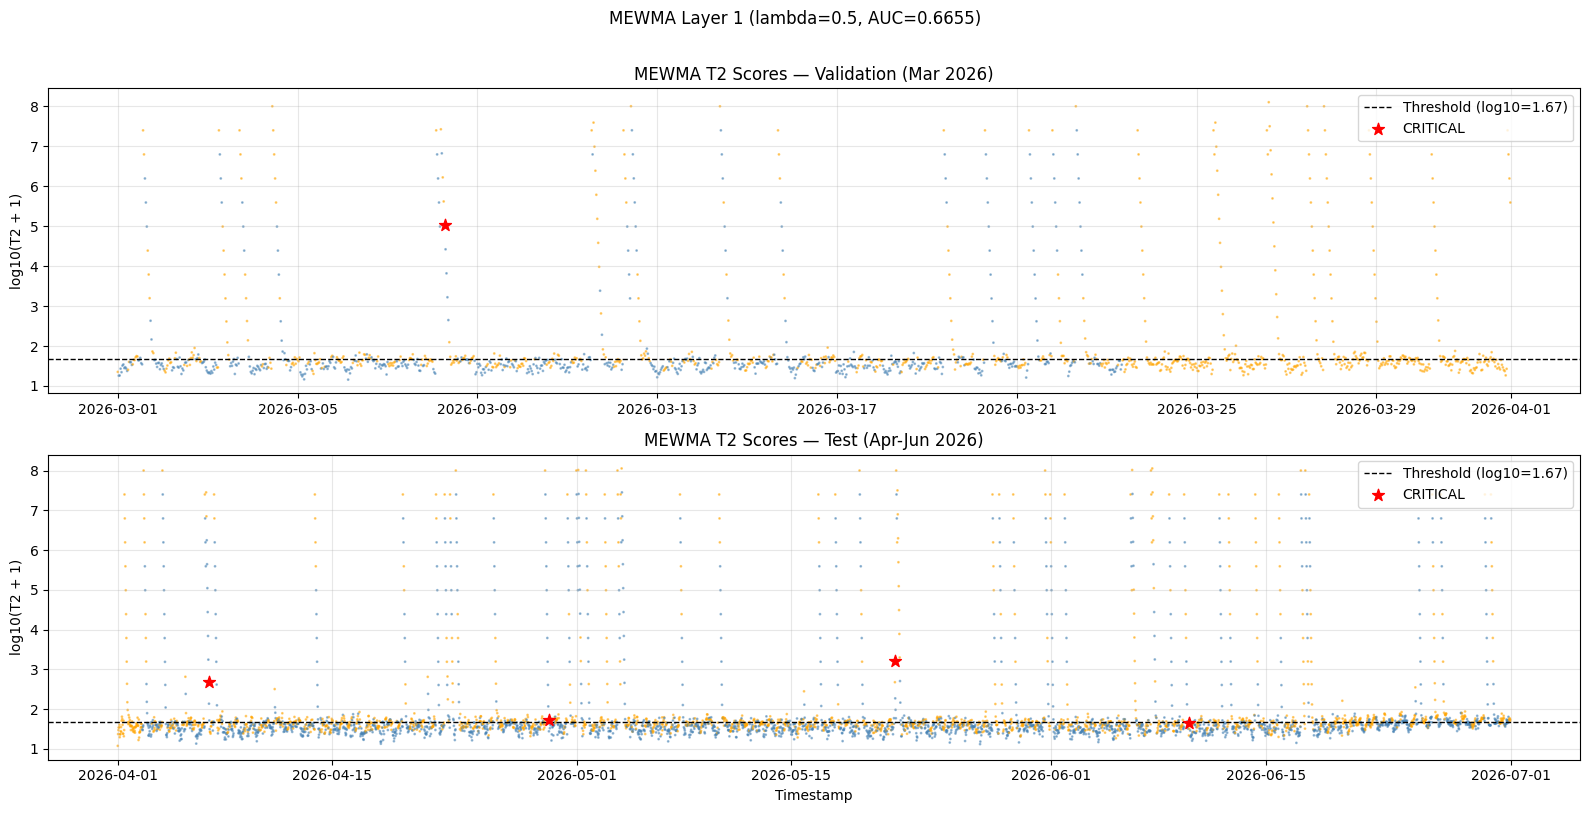

Saved: /content/drive/MyDrive/Tugas Pak Imam/Teknis 2/artifacts/fig05_mewma_scores.png

RINGKASAN NOTEBOOK 04 - MEWMA (Layer 1)
Best lambda     : 0.5
Best percentile : 90
Best threshold  : 45.27
Validation AUC  : 0.6655
Validation F1   : 0.5393

CRITICAL detection:
  Val  : 1/1 detected
  Test : 3/4 detected (1 missed by margin of 2.25)

Key insight:
  MEWMA alone achieves moderate AUC (0.67), confirming the need
  for Layer 2 (BiLSTM-AE) to capture complex temporal patterns
  that statistical control charts miss.

NEXT: 05_model_bilstm_ae.ipynb



In [6]:
# --- Visualisasi MEWMA T2 scores ---
# Tujuan : Plot T2 scores pada val dan test dengan threshold dan CRITICAL markers
# Input  : mewma_results
# Output : fig05_mewma_scores.png

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

for ax, split_name, timestamps, t2_raw, y_true, severity in [
    (axes[0], "Validation (Mar 2026)",
     val_df["timestamp"].values, t2_val_final,
     val_df["is_anomaly_proxy"].values, val_df["anomaly_severity_proxy"].values),
    (axes[1], "Test (Apr-Jun 2026)",
     test_df["timestamp"].values, t2_test_final,
     test_df["is_anomaly_proxy"].values, test_df["anomaly_severity_proxy"].values),
]:
    # Log scale for readability given extreme range
    t2_plot = np.log10(t2_raw + 1)
    thresh_plot = np.log10(BEST_THRESHOLD + 1)

    # Color by proxy label
    colors = np.where(severity == "CRITICAL", "red",
             np.where(y_true == 1, "orange", "steelblue"))

    ax.scatter(timestamps, t2_plot, c=colors, s=1, alpha=0.5)
    ax.axhline(thresh_plot, color="black", linestyle="--", linewidth=1,
               label=f"Threshold (log10={thresh_plot:.2f})")

    # Mark CRITICAL
    crit_mask = severity == "CRITICAL"
    if crit_mask.any():
        ax.scatter(timestamps[crit_mask], t2_plot[crit_mask],
                   c="red", s=80, marker="*", zorder=5, label="CRITICAL")

    ax.set_title(f"MEWMA T2 Scores — {split_name}")
    ax.set_ylabel("log10(T2 + 1)")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Timestamp")
fig.suptitle(f"MEWMA Layer 1 (lambda={BEST_LAMBDA}, AUC={best_row['AUC']:.4f})", y=1.01)
plt.tight_layout()

fig_path = os.path.join(DRIVE_DIR, "fig05_mewma_scores.png")
plt.savefig(fig_path, bbox_inches="tight")
plt.show()

print(f"Saved: {fig_path}")

print(f"""
RINGKASAN NOTEBOOK 04 - MEWMA (Layer 1)
========================================
Best lambda     : {BEST_LAMBDA}
Best percentile : {BEST_PCT:.0f}
Best threshold  : {BEST_THRESHOLD:.2f}
Validation AUC  : {best_row['AUC']:.4f}
Validation F1   : {best_row['F1']:.4f}

CRITICAL detection:
  Val  : 1/1 detected
  Test : 3/4 detected (1 missed by margin of 2.25)

Key insight:
  MEWMA alone achieves moderate AUC (0.67), confirming the need
  for Layer 2 (BiLSTM-AE) to capture complex temporal patterns
  that statistical control charts miss.

NEXT: 05_model_bilstm_ae.ipynb
""")